<center><img src="https://upload.wikimedia.org/wikipedia/commons/9/96/Pytorch_logo.png" width="500" height="600"></center>

# <center><b><span style='color:#FF9B9B'>Introduction to LSTMs</span></b></center>


### <b><span style='color:#FF9B9B'>What will you learn?</span></b>

- The theoretical background on how LSTMs work.
- Learn the different components of the LSTM network architecture, like LSTM layers, cells and gates.

This notebook was inspired by Michael Phi's [Illustrated Guide to LSTM's and GRU's: A step by step explanation](https://www.youtube.com/watch?v=8HyCNIVRbSU) so support him by giving the thumb's up 👍🏼!

### <b><span style='color:#FF9B9B'>Table of Contents</span></b><a class='anchor' id='top'>

The notebook will be divided into separate sections to provide an organized walk-through. The sections are:

<div style=" background-color:#3b3745; padding: 13px 13px; border-radius: 8px; color: white">  
<ol>
    <li><a href="#introduction">Introduction</a></li>
    <li><a href="#layers_cells">LSTM Layers and LSTM Cells</a></li>
        <ul>
            <li><a href="#layer">LSTM Layer</a></li>
            <li><a href="#cell">LSTM Cell</a></li>
            <li><a href="#similarity">Similarities with Linear Layers</a></li>
        </ul>
    <li><a href="#cell">States</a></li>
         <ul>
            <li><a href="#cell_state">Cell State</a></li>
            <li><a href="#hidden_state">Hidden State</a></li>
        </ul>
    <li><a href="#gates">Gates</a></li>
        <ul>
            <li><a href="#forget">Forget Gate</a></li>
            <li><a href="#input">Input Gate</a></li>
            <li><a href="#output">Output Gate</a></li>
        </ul>
    <li><a href="#import_libraries">Import Libraries</a></li>
    <li><a href="#layer_pytorch">LSTM Layer PyTorch</a></li>
    <li><a href="#example">Minimal Example: Feeding 2 Sentences to an LSTM</a></li>
        <ul>
            <li><a href="#ex1">Create vocabulary</a></li>
            <li><a href="#ex2">Create indices to vectorize words</a></li>
            <li><a href="#ex3">Vectorize sentences</a></li>
            <li><a href="#ex4">Define Embedding layer</a></li>
            <li><a href="#ex5">Push batch through Embedding layer</a></li>
            <li><a href="#ex6">Define LSTM layer</a></li>
            <li><a href="#ex7">Push batch through LSTM layer</a></li>
        </ul>
    <li><a href="#references">References</a></li>
</ol> 
</div> 

# <b>1 <span style='color:#FF9B9B'>|</span> Introduction</b><a class='anchor' id='introduction'></a> [↑](#top) 
***

LSTM networks were first proposed by Sepp Hochreiter and Jürgen Schmidhuber in 1997 as a solution to the vanishing gradient problem in standard recurrent neural networks (RNNs). The vanishing gradient problem occurs when the gradients used to update the weights of a neural network become very small, making it difficult for the network to learn long-term dependencies in the input data.

An LSTM network is a type of neural network that is specifically designed to process sequences of data, such as time series or natural language. The network is composed of multiple LSTM layers, which are stacked on top of one another to form a deep neural network.

Each LSTM layer is composed of a number of LSTM cells. An LSTM cell is a single processing unit within an LSTM layer that is capable of storing information over time. It consists of several components, including a memory cell, an input gate, a forget gate, and an output gate.

$$ LSTM\:Network \: \xrightarrow{\text{composed of}} \: LSTM\:Layers \: \xrightarrow{\text{composed of}} \: LSTM\:Cells \: \xrightarrow{\text{composed of}} Gates$$


This is a basic diagram of the LSTM architecture, we will come back to it many times throughout this notebook:

<center><img src="https://miro.medium.com/v2/resize:fit:1400/format:webp/1*xRe8z9Znm2CqGeeYRwfmBw.png" width="450"></center>

The basic idea behind LSTMs is to introduce a set of memory cells that can store information for an extended period of time. Each memory cell is equipped with three gates - an input gate, an output gate, and a forget gate - which control the flow of information into and out of the cell.

The input gate decides which information to add to the memory cell, while the forget gate determines which information to remove from the cell. The output gate controls the flow of information out of the cell and into the next layer of the network.

By allowing the network to selectively retain or discard information over time, LSTMs are able to learn long-term dependencies in the input data more effectively than traditional RNNs.

Over the years, LSTMs have become an increasingly popular choice for a wide range of applications, including speech recognition, natural language processing, and time series analysis. They have also been extended and modified in various ways, such as adding peephole connections, using different activation functions, and introducing multiple layers.

Today, LSTMs remain one of the most widely used types of neural networks, and they continue to be an active area of research in the field of deep learning.



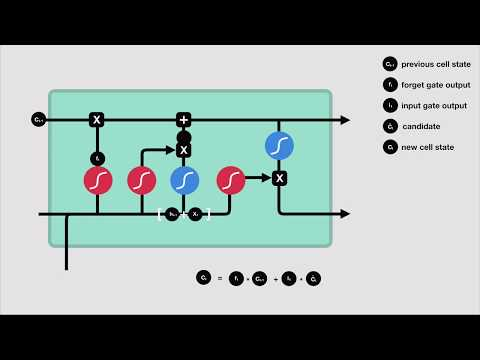

In [1]:
from IPython.display import YouTubeVideo

YouTubeVideo('8HyCNIVRbSU', width=800, height=300)

# <b>2 <span style='color:#FF9B9B'>|</span> LSTM Layers and LSTM Cells</b><a class='anchor' id='layers_cells'></a> [↑](#top) 
***

### <b><span style='color:#FF9B9B'>LSTM Layer</span></b><a class='anchor' id='layer'></a>[↑](#top)

An **LSTM layer** (Long Short-Term Memory) is a type of recurrent neural network (RNN) layer that is commonly used in deep learning for sequence modeling tasks, such as language modeling, speech recognition, and time series prediction. An LSTM layer contains multiple LSTM cells, which are the basic building blocks of the layer. 

The image represents an **LSTM Neural Network**, the **green blocks** are **LSTM Cells** (except of course for the FC layers), while the groups of these cells with the same number are the **LSTM Layers**. For example, **all LSTM cells numbered** 1 compose the **LSTM Layer** 1. This network also has some Fully Connected Layers (FCL) in the end. So, in the image:
1. There are *T* number of LSTM cells per layer.
2. The are *2* LSTM layers.
2. The are *2* Fully Connected layers.

<center><img src="https://i.imgur.com/Vopolyl.png" width="800"></center>

### <b><span style='color:#FF9B9B'>LSTM Cell</span></b><a class='anchor' id='cell'></a>[↑](#top)

An **LSTM cell** is a specific type of RNN cell that is designed to address the vanishing gradient problem that can occur when training traditional RNNs on long sequences of data. The LSTM cell is composed of several gates, which are used to control the flow of information through the cell. The gates include the input gate, forget gate, and output gate, each of which serves a specific purpose in determining which information is passed through the cell.

<center><img src="https://upload.wikimedia.org/wikipedia/commons/thumb/9/93/LSTM_Cell.svg/1280px-LSTM_Cell.svg.png" width="450"></center>

So, the main difference between an LSTM layer and an LSTM cell is that the layer is a higher-level structure that contains multiple cells, while the cell is the basic unit that processes the sequence data and controls the flow of information.

### <b><span style='color:#FF9B9B'>Similarities with Linear Layers</span></b><a class='anchor' id='similarity'></a>[↑](#top)

There are some similarities between the relationship of LSTM cells to LSTM layers and the relationship of Neurons to Linear layers, but the two relationships are not exactly the same.

In both cases, the lower-level building blocks (LSTM cells or neurons) perform a specific function on the input data, and the higher-level structures (LSTM layers or linear layers) combine the outputs of the lower-level building blocks to produce a final output. So in a certain way or analogy you could think that "neurons are to linear layers what LSTM cells are to LSTM layers".

However, there are some important differences. Firstly, LSTM cells are specifically designed for processing sequential data, while neurons in a linear layer can be used for processing any kind of data. Secondly, while LSTM cells have a complex structure with multiple internal components (such as input gates, output gates, and memory cells) that allow them to handle long-term dependencies in sequential data, neurons in a linear layer typically have a simpler structure with only one or a few learnable parameters.

So while LSTM cells and neurons both serve as the basic building blocks of their respective layers, the specific functions they perform and the complexity of their internal structure are different.

# <b>3 <span style='color:#FF9B9B'>|</span> States</b><a class='anchor' id='states'></a> [↑](#top) 
***





### <b><span style='color:#FF9B9B'>Cell State</span></b><a class='anchor' id='cell_state'></a> [↑](#top) 

The **cell states** act as a "transport highway" that transfers relative information all the way down to the sequence of LSTM cells. We can think about it as the memory of the network. Because the cell states can carry information throughout the sequence of LSTM cells in theory even information from earlier time steps could be carried all the way to the last time step thus reducing the effects of short-term memory.

<center><img src="https://i.imgur.com/k5cU8h3.gif" width=600></center>
<br>

The cell state is calculated by the following formula:
$$c_{t} = f_{t} \ast c_{t-1} + i_{t} \ast g_{t}$$

Where:

- $f_{t}$ is the forget gate output.
- $c_{t-1}$ is the previous cell state.
- $i_{t}$ is the input gate output.
- $g_{t}$ is the cell gate output.

### <b><span style='color:#FF9B9B'>Hidden State</span></b><a class='anchor' id='hidden_state'></a> [↑](#top) 

The **hidden state** is a vector of values that is updated at each time step as the network processes input sequences.

The hidden state is used to capture and store information about the input sequence that has been processed so far, and this information is passed along to the next time step. The hidden state serves as a kind of "memory" for the network, allowing it to keep track of important features of the input sequence as it processes it.

The LSTM architecture is designed to allow the network to selectively remember or forget information in the hidden state using special gating mechanisms. These gates allow the network to control the flow of information through the hidden state, which can help to prevent the network from overfitting or forgetting important features of the input sequence.

# <b>4 <span style='color:#FF9B9B'>|</span> Gates</b><a class='anchor' id='gates'></a> [↑](#top) 
***

So we have three different types of gates that regulate information flow in an LSTM cell:
1. Forget Gate
2. Input Gate
3. Output Gate

<center><img src="https://i.imgur.com/OglRflQ.png" width="450"></center>


### <b><span style='color:#FF9B9B'>Forget Gate</span></b><a class='anchor' id='forget'></a>[↑](#top)

The **forget gate** decides what information should be thrown or kept away. Information from a previous hidden state $h_{t-1}$ and the information from the current input $x_{t}$ are concatenated and passed through the sigmoid function. Values come out between 0 and 1. The closer to 0 means "forget" and a closer to 1 means "keep" 

<center><img src="https://i.imgur.com/OXywwAR.gif" width=600></center>
<br>

### <b><span style='color:#FF9B9B'>Input Gate</span></b><a class='anchor' id='input'></a>[↑](#top)

To update the cell state we have the **input gate**. The input gate consists of two parts: one with a sigmoid function and another one with a hyperbolic tangent function (usually called the cell gate). Just as with the forget gate, both are input the concatenation of $h_{t-1}$ and $x_{t}$. The sigmoid part is exactly as the forget gate, the tanh part squish values between -1 and 1 which helps to regulate the network. Both parts are multiplied which in essence means that the sigmoid output decides which information is important to keep from the tanh output.

<center><img src="https://i.imgur.com/10fHN8Y.gif" width=600></center>
<br>

### <b><span style='color:#FF9B9B'>Output Gate</span></b><a class='anchor' id='output'></a>[↑](#top)

The **output gate** decides what the next hidden state should be. First $h_{t-1}$ and $x_{t}$ are passed once again through a sigmoid function. Then the current cell state is passed through a hyperbolic tangent function. We then multiply the sigmoid output with the tanh output. This decides which information from the cell state the hidden state should carry. 

<center><img src="https://i.imgur.com/RQ5pKLH.gif" width=600></center>
<br>

The LSTM outputs the next time step's input cell state an input hidden state.

# <b>5 <span style='color:#FF9B9B'>|</span> Import Libraries</b><a class='anchor' id='import_libraries'></a> [↑](#top) 
***

In [2]:
import numpy as np
import os
import torch
import torch.nn as nn

# <b>6 <span style='color:#FF9B9B'>|</span> LSTM Layer PyTorch</b><a class='anchor' id='layer_pytorch'></a> [↑](#top) 
***

<center><img src="https://miro.medium.com/v2/resize:fit:1400/format:webp/1*xRe8z9Znm2CqGeeYRwfmBw.png" width="600"></center>

In [3]:
BATCH_SIZE = 8 # Number of sequences in your batch
HIDDEN_SIZE = 16 # Number of features in the hidden state 
INPUT_SIZE = 384 # Size of each embedding in the sequence
NUM_LAYERS = 2 # Number of LSTM layers in the LSTM network
SEQUENCE_LENGTH = 50 # Number of embeddings per sequence

# === LSTM Network ===
LSTM = nn.LSTM(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,        
    num_layers=NUM_LAYERS,       
    batch_first=True
)

inputs = torch.randn(BATCH_SIZE, SEQUENCE_LENGTH, INPUT_SIZE) # LSTM Network input
h0 = torch.randn(NUM_LAYERS, BATCH_SIZE, HIDDEN_SIZE) # Initial Hidden state
c0 = torch.randn(NUM_LAYERS, BATCH_SIZE, HIDDEN_SIZE) # Initial Cell state
outputs, (hn, cn) = LSTM(inputs, (h0, c0)) # LSTM Network output

print(f"Input batch shape: {inputs.shape}")
print(f"Hidden state 0 shape: {h0.shape}")
print(f"Cell state 0 shape: {c0.shape}")
print(f"Output batch shape: {outputs.shape}")

Input batch shape: torch.Size([8, 50, 384])
Hidden state 0 shape: torch.Size([2, 8, 16])
Cell state 0 shape: torch.Size([2, 8, 16])
Output batch shape: torch.Size([8, 50, 16])


# <b>7 <span style='color:#FF9B9B'>|</span> Minimal Example: Feeding 2 Sentences to an LSTM</b><a class='anchor' id='example'></a> [↑](#top) 
***

The author of this example is @chrisvdweth. You can find the source [code](https://github.com/chrisvdweth/ml-toolkit/blob/master/pytorch/notebooks/minimal-example-lstm-input.ipynb) in his GitHub.


### <b><span style='color:#FF9B9B'>Create vocabulary</span></b><a class='anchor' id='ex1'></a>[↑](#top)

In [4]:
sentences = ['i like fresh bread', 'i hate stale bread']

vocabulary = set()
for sent in sentences:
    for word in sent.split():
        vocabulary.add(word)

print(vocabulary)

{'stale', 'hate', 'i', 'like', 'bread', 'fresh'}


### <b><span style='color:#FF9B9B'>Create indices to vectorize words</span></b><a class='anchor' id='ex2'></a>[↑](#top)

In [5]:
# Most NLP tasks require some basic tokens, e.g., for padding, unknown words, start of sequence, end of sequence
word2index = {'<PAD>': 0, '<UNK>': 1, '<SOS>': 2, '<EOS>': 3}

for word in vocabulary:
    word2index[word] = len(word2index)
    
print(word2index)

{'<PAD>': 0, '<UNK>': 1, '<SOS>': 2, '<EOS>': 3, 'stale': 4, 'hate': 5, 'i': 6, 'like': 7, 'bread': 8, 'fresh': 9}


### <b><span style='color:#FF9B9B'>Vectorize sentences</span></b><a class='anchor' id='ex3'></a>[↑](#top)

In [6]:
batch = [[word2index[word] for word in sent.split()] for sent in sentences]

print(batch)
print()

# Let's make a numpy array out of it
batch = np.array(batch)

print(batch)
print('The shape of batch is:', batch.shape)
print()

# Let's make a PyTorch tensor out of it
batch = torch.tensor(batch, dtype=torch.long)
print(batch)
print('The shape of batch is:', batch.shape)

[[6, 7, 9, 8], [6, 5, 4, 8]]

[[6 7 9 8]
 [6 5 4 8]]
The shape of batch is: (2, 4)

tensor([[6, 7, 9, 8],
        [6, 5, 4, 8]])
The shape of batch is: torch.Size([2, 4])


### <b><span style='color:#FF9B9B'>Define Embedding layer</span></b><a class='anchor' id='ex4'></a>[↑](#top)

The Embedding layer is like a look-up table. You can imagine it like a dictionary, where the keys are the words in our vocabulary and the values are embeddings. 

An embedding in deep learning refers to a process of mapping an input object, such as a word, a categorical variable or even an image, to a continuous **vector** space, usually with a lower dimensionality.

Embeddings are widely used in natural language processing (NLP) tasks to represent words or phrases in a way that **captures their semantic relationships**. In such cases, the embedding is typically learned by training a neural network on a large corpus of text data.

So in simple terms, embeddings are numerical vectors which represent an object and capture the characteristics and relationships of these original objects. For example, the embedding of the word *king* plus the embedding of the word *man* minus the embedding of the word *woman* gives you the embedding of the word *queen*.

$$e_{queen} \approx e_{king} + e_{man} - e_{woman}$$

However, each word embedding in this example is a random vector which has no semantic meaning.

In [7]:
vocab_size = len(word2index)   # vocab_size reflects all known words in the index
embed_dim = 10                 # Let's assume the word embeddings are of size 10 to keep it simple
word_embedding_layer = nn.Embedding(vocab_size, embed_dim)

### <b><span style='color:#FF9B9B'>Push batch through Embedding layer</span></b><a class='anchor' id='ex5'></a>[↑](#top)

In [8]:
batch = word_embedding_layer(batch)

print('The shape of batch is:', batch.shape)
print()
print(batch)

The shape of batch is: torch.Size([2, 4, 10])

tensor([[[-0.0317, -1.2512, -1.5770, -0.3342,  0.3294, -1.5575, -0.4019,
           2.5394,  1.7278, -0.0837],
         [ 0.2781, -0.4798, -1.1132,  1.0540,  2.2116, -1.0221, -1.6100,
          -0.0656, -0.8386, -0.2397],
         [ 1.1271,  0.2417,  0.2286, -0.2421,  0.4329,  1.9341,  1.2222,
           1.4581,  0.5787,  3.9291],
         [ 1.2770, -0.3274,  1.1133,  2.3094,  0.3646,  0.4957, -0.2828,
           0.1373,  2.3211,  0.4657]],

        [[-0.0317, -1.2512, -1.5770, -0.3342,  0.3294, -1.5575, -0.4019,
           2.5394,  1.7278, -0.0837],
         [ 1.9014,  0.9359, -1.1905,  2.0028,  0.4031,  0.4012, -1.0203,
          -1.4966,  0.3808,  0.9758],
         [-0.3561,  1.1257,  0.0412, -1.6334, -0.6553,  1.4735,  2.1123,
          -1.1066,  0.6742,  0.2389],
         [ 1.2770, -0.3274,  1.1133,  2.3094,  0.3646,  0.4957, -0.2828,
           0.1373,  2.3211,  0.4657]]], grad_fn=<EmbeddingBackward0>)


### <b><span style='color:#FF9B9B'>Define LSTM layer</span></b><a class='anchor' id='ex6'></a>[↑](#top)

In [9]:
hidden_dim = 32 # Let's set the size if the hidden dimension to 32

lstm  = nn.LSTM(embed_dim,
                hidden_dim,
                batch_first=True)

### <b><span style='color:#FF9B9B'>Push batch through LSTM layer</span></b><a class='anchor' id='ex7'></a>[↑](#top)

In [10]:
# Initialize hidden state (here with zeros)
batch_size = batch.shape[0]
(h, c) =  (torch.zeros(1, batch_size, hidden_dim), torch.zeros(1, batch_size, hidden_dim)) 

lstm_out, (h, c) = lstm(batch, (h, c))

print('The shape of lstm_out is:', lstm_out.shape) # (batch_size, seq_len, hidden_dim)
print('The shape of h is:', h.shape) # (num_layers*num_directions, batch_size, hidden_dim)

The shape of lstm_out is: torch.Size([2, 4, 32])
The shape of h is: torch.Size([1, 2, 32])


# <b> <span style='color:#FF9B9B'>|</span> References</b><a class='anchor' id='references'></a> [↑](#top) 
***

To get a better understanding of LSTMs these are some good readings and videos:
1. [PyTorch documentation on LSTM Cell](https://pytorch.org/docs/stable/generated/torch.nn.LSTMCell.html#lstmcell)
2. [PyTorch documentation on LSTM Layer](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html#torch.nn.LSTM)
2. [Illustrated Guide to LSTM's and GRU's](https://www.youtube.com/watch?v=8HyCNIVRbSU)
3. [Understanding LSTM Networks](https://colah.github.io/posts/2015-08-Understanding-LSTMs/)
4. [Implementation Differences in LSTM Layers](https://towardsdatascience.com/implementation-differences-in-lstm-layers-tensorflow-vs-pytorch-77a31d742f74#:~:text=The%20output%20of%20the%20Pytorch,another%20tuple%20with%20two%20elements.)